# Lab 3 · Virtual flow metering (VFM)
**Slides:** Module 03 (production applications), 06 and 07  ·  **Time:** 75 min

A test separator measures oil, water and gas only occasionally. A **virtual flow meter** estimates the rates
continuously from gauges the well already has: choke size, bottom-hole and wellhead pressure, wellhead temperature,
separator pressure and temperature. The course notebook `VFM.ipynb` compares XGBoost, Extra Trees, CatBoost, random
forest and a neural network.

**You will:** find and fix a leakage problem · compare models with a group split · predict three phases · test extrapolation to an unseen choke · run a what-if.

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("aiml"):
    print("Upload the course kit zip to Colab, then unzip it:  !unzip -q aiml_course_kit.zip && %cd aiml_course_kit")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data" if os.path.exists("../data") else "data"

from aiml.data import load_vfm, VFM_FEATURES, VFM_TARGETS
from aiml.models import regressors
from aiml.evaluate import compare, crossplot, report, importance
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, KFold, cross_val_score
from sklearn.metrics import r2_score
df = load_vfm()
print(len(df), "rows ·", df.case_id.nunique(), "different well tests"); df.head()

2100 rows · 972 different well tests


,choke_in,bhp_psi,whp_psi,wht_F,psep_psi,tsep_F,oil_rate_stb_d,water_rate_bbl_d,gas_rate_mmscf_d,case_id,liquid_rate_bbl_d
0,0.25,5410.33,3185.75,83.30,100,60.32,954.6,0.0,2.39,0,954.6
1,0.25,5388.00,3015.38,86.88,100,60.65,801.9,200.5,2.01,1,1002.4
2,0.25,5391.13,2808.80,90.83,100,61.19,634.7,423.2,1.59,2,1057.9
3,0.25,5405.72,2515.99,95.11,100,61.97,448.1,672.2,1.12,3,1120.3
4,0.25,5433.80,2059.65,99.88,100,63.10,238.9,955.7,0.60,4,1194.6


## 1 · Why the course notebook scores R² ≈ 1.000
Each test appears once per separator pressure. Compare a random split with a split by `case_id`.

In [2]:
from sklearn.ensemble import ExtraTreesRegressor
X, y = df[VFM_FEATURES], df["oil_rate_stb_d"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=123)
et = ExtraTreesRegressor(n_estimators=300, random_state=0).fit(Xtr, ytr); report(yte, et.predict(Xte), "random split")
g = [c for c in VFM_FEATURES if c != "psep_psi"]
print("test rows whose well test is also in training (only Psep differs):", Xte[g].merge(Xtr[g].drop_duplicates(), how="inner").shape[0], "of", len(Xte))
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)
tr, te = next(gss.split(X, y, groups=df.case_id))
et.fit(X.iloc[tr], y.iloc[tr]); report(y.iloc[te], et.predict(X.iloc[te]), "split by case_id")

random split                 R2 1.000  MAE 8.413  RMSE 23.509  MAPE 0.4%
test rows whose well test is also in training (only Psep differs): 280 of 420


split by case_id             R2 0.994  MAE 49.522  RMSE 122.675  MAPE 3.1%


{'R2': 0.9939688912637321,
 'MAE': 49.52249617737274,
 'RMSE': 122.67523358595064,
 'MAPE_%': np.float64(3.098047379431806)}

The drop is small here because the tests are dense, but the random-split number was not an honest estimate. From now on: **group split**.

In [3]:
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
keep = ["Linear regression", "KNN", "Decision tree", "Random forest", "Extra trees", "Gradient boosting", "Hist. gradient boosting (XGBoost-style)", "Neural network (MLP)"]
res = compare({k: v for k, v in regressors().items() if k in keep}, X_train, y_train, X_test, y_test)
res[["model", "R2_train", "R2_test", "MAE_test", "MAPE_%_test", "fit_s"]]

,model,R2_train,R2_test,MAE_test,MAPE_%_test,fit_s
0,Neural network (MLP),1.0000,0.9999,10.9219,0.6378,5.1647
1,Extra trees,1.0000,0.9940,49.5225,3.0980,0.6098
2,Random forest,0.9999,0.9884,90.6220,4.4782,0.8786
3,Hist. gradient boosting (XGBoost-style),0.9998,0.9808,93.9580,4.8209,0.6969
4,KNN,1.0000,0.9796,148.7313,8.6532,0.0030
5,Gradient boosting,0.9973,0.9779,136.3921,7.7664,0.5870
6,Decision tree,0.9970,0.9744,138.5104,5.8685,0.0036
7,Linear regression,0.9303,0.9302,345.7518,20.1610,0.0035


### ✏️ Your turn 1 · 10-fold cross-validation, done right
The notebook uses `KFold(10, shuffle=True)`. Repeat it for *Extra trees* with `KFold` and with `GroupKFold(10)` (groups = `case_id`). Which is optimistic?

In [4]:
m = regressors()["Extra trees"]
a = cross_val_score(m, X, y, cv=KFold(10, shuffle=True, random_state=123), scoring="r2")
b = cross_val_score(m, X, y, cv=GroupKFold(10), groups=df.case_id, scoring="r2")
print(f"KFold      R² {a.mean():.4f} ± {a.std():.4f}"); print(f"GroupKFold R² {b.mean():.4f} ± {b.std():.4f}  (honest)")

KFold      R² 0.9998 ± 0.0001
GroupKFold R² 0.9972 ± 0.0022  (honest)


## 2 · Cross-plots and residuals

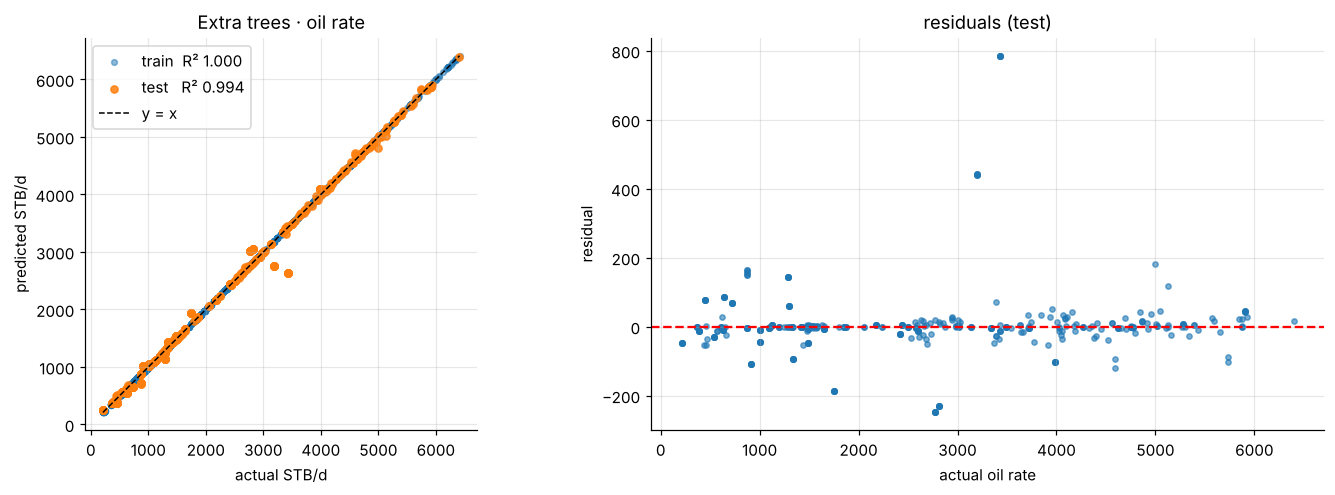

In [5]:
best = regressors()["Extra trees"].fit(X_train, y_train)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
crossplot(y_train, best.predict(X_train), y_test, best.predict(X_test), "Extra trees · oil rate", "STB/d", ax=ax[0])
ax[1].scatter(y_test, y_test - best.predict(X_test), s=12, alpha=.6); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("actual oil rate"); ax[1].set_ylabel("residual"); ax[1].set_title("residuals (test)"); plt.tight_layout(); plt.show()

## 3 · Three phases
One model per phase. Which phase is hardest to meter virtually?

In [6]:
rows = []
for t in VFM_TARGETS:
    m = regressors()["Extra trees"].fit(X_train, df[t].iloc[tr]); p = m.predict(X_test)
    rows.append({"target": t, **{k: round(v, 4) for k, v in report(df[t].iloc[te], p, t).items()}})
pd.DataFrame(rows)

oil_rate_stb_d               R2 0.994  MAE 49.522  RMSE 122.675  MAPE 3.1%


water_rate_bbl_d             R2 0.997  MAE 38.254  RMSE 90.758  MAPE 3.6%


gas_rate_mmscf_d             R2 0.998  MAE 0.159  RMSE 0.281  MAPE 1.9%


,target,R2,MAE,RMSE,MAPE_%
0,oil_rate_stb_d,0.9940,49.5225,122.6752,3.0980
1,water_rate_bbl_d,0.9973,38.2541,90.7582,3.6045
2,gas_rate_mmscf_d,0.9980,0.1588,0.2810,1.9208


## 4 · Extrapolation: a choke the model never saw
Hold out every test at one choke size and train on the other nine. Interpolating between chokes (0.70 in) is very different
from going beyond the data, and tree models cannot predict outside the range they saw.

In [7]:
rows = []
for c in [0.25, 0.70, 1.94, 2.50]:
    m_tr = df.choke_in != c
    for name in ["Extra trees", "Hist. gradient boosting (XGBoost-style)", "Neural network (MLP)", "Linear regression"]:
        m = regressors()[name].fit(X[m_tr], y[m_tr])
        rows.append({"held-out choke (in)": c, "model": name, "R2": round(r2_score(y[~m_tr], m.predict(X[~m_tr])), 3)})
pd.DataFrame(rows).pivot(index="model", columns="held-out choke (in)", values="R2")

held-out choke (in),0.25,0.70,1.94,2.50
model,,,,
Extra trees,-11.158,0.674,0.999,0.997
Hist. gradient boosting (XGBoost-style),-5.463,0.449,0.997,0.991
Linear regression,-3.027,0.826,0.858,0.858
Neural network (MLP),-0.178,0.925,0.987,0.878


### ✏️ Your turn 2 · what-if
Keep a mid-life well (BHP 4700 psi, WHT 150 °F, Psep 300 psi, Tsep 100 °F) and vary the choke from 0.25 to 2.5 in.
Feed WHP from the test closest to each choke and plot the predicted oil rate. Why does the curve flatten above ~1.2 in?

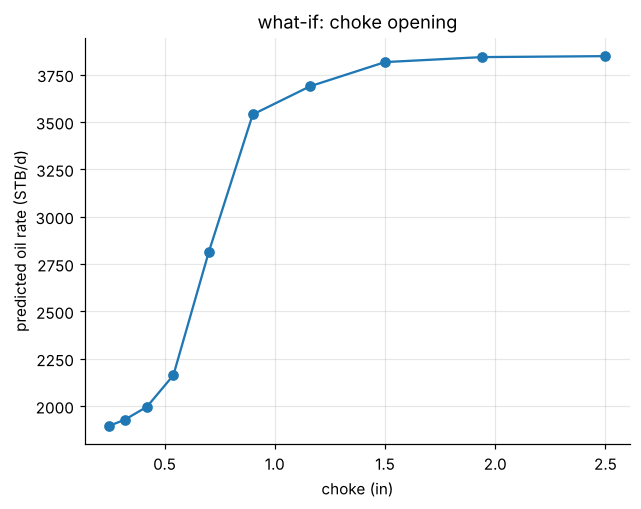

Above ~1.2 in the choke stops controlling the flow: the reservoir and tubing limit the rate (subcritical flow).


In [8]:
chokes = np.sort(df.choke_in.unique())
whp = df.groupby("choke_in").whp_psi.median()
q = best.predict(pd.DataFrame({"choke_in": chokes, "bhp_psi": 4700, "whp_psi": whp[chokes].values, "wht_F": 150, "psep_psi": 300, "tsep_F": 100}))
plt.plot(chokes, q, "o-"); plt.xlabel("choke (in)"); plt.ylabel("predicted oil rate (STB/d)"); plt.title("what-if: choke opening"); plt.show()
print("Above ~1.2 in the choke stops controlling the flow: the reservoir and tubing limit the rate (subcritical flow).")

## 5 · Which gauges matter?

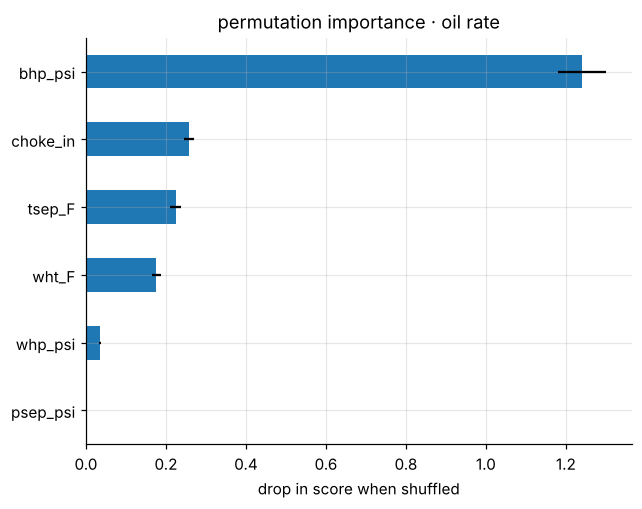

In [9]:
importance(best, X_test, y_test); plt.title("permutation importance · oil rate"); plt.show()

### ✏️ Your turn 3 · a failed gauge
The wellhead pressure gauge fails. Retrain without `whp_psi` and compare the test R². Which other gauge takes over?

## Key ideas
* Duplicated rows make a random split leak: always ask "how many independent tests do I have?".
* VFM interpolates well; extrapolation to unseen operating conditions needs physics or new tests.
* On this data the six gauges predict all three phases well (test R² about 0.99 with a group split).
* An unseen choke size is the real weakness: the meter is reliable only inside the conditions it was trained on.
* Permutation importance shows which gauges the meter depends on, and what a failed gauge costs.

without WHP                  R2 0.995  MAE 48.597  RMSE 116.895  MAPE 2.7%


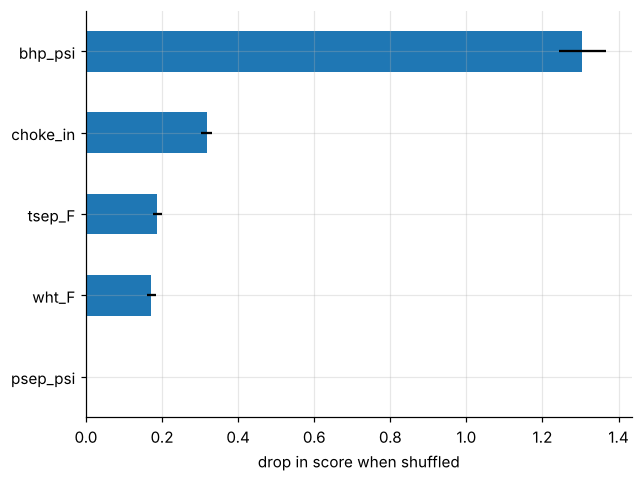

In [10]:
F2 = [f for f in VFM_FEATURES if f != "whp_psi"]
m2 = regressors()["Extra trees"].fit(X_train[F2], y_train); report(y_test, m2.predict(X_test[F2]), "without WHP")
importance(m2, X_test[F2], y_test); plt.show()